# Recorridos: grafos eulerianos y hamiltonianos

**Matemática Discreta (2026/27)** · Edgar Martínez-Moro · Departamento de Matemática Aplicada, Escuela de Ingeniería Informática, Universidad de Valladolid

Este cuaderno acompaña a la sesión 15 del tema de **teoría de grafos**. Contiene:

1. Grafos eulerianos: el teorema de Euler y su corolario.
2. El algoritmo de Fleury, paso a paso.
3. El algoritmo de Hierholzer y una comparación de tiempos.
4. Caminos y ciclos hamiltonianos por vuelta atrás.
5. Las condiciones suficientes del teorema 4.30.

## Repaso

- Una **cola euleriana** recorre todas las aristas sin repetir ninguna; si es cerrada, es un **circuito euleriano**.
- **Teorema de Euler.** Un grafo conexo tiene un circuito euleriano si y sólo si todos sus grados son pares, y una cola euleriana si y sólo si tiene $0$ o $2$ vértices de grado impar.
- Un **camino hamiltoniano** pasa una vez por cada vértice; si es cerrado, es un **ciclo hamiltoniano**. No se conoce ninguna caracterización sencilla ni ningún algoritmo eficiente.

Para dibujar los grafos usamos una función sencilla con `matplotlib`: las posiciones de los vértices se dan a mano.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch



def dibujar(pos, aristas, dirigido=False, pesos=None, resaltar=(), titulo=None,
            tam=(4, 3), radio=0.22):
    """
    pos: {vértice: (x, y)}; aristas: lista de pares (o de ternas con peso).
    Las aristas repetidas se dibujan curvadas; los lazos, como un pequeño círculo.
    resaltar: aristas que se pintan en rojo.
    """
    fig, ax = plt.subplots(figsize=tam)
    resaltar = {frozenset(a[:2]) for a in resaltar} if not dirigido else {tuple(a[:2]) for a in resaltar}
    vistas, total = {}, {}
    for a in aristas:
        clave = (a[0], a[1]) if dirigido else frozenset((a[0], a[1]))
        total[clave] = total.get(clave, 0) + 1
    for a in aristas:
        x, y = a[0], a[1]
        if not dirigido and str(x) > str(y):
            x, y = y, x                      # mismo sentido para curvar las múltiples
        w = a[2] if len(a) > 2 else None
        clave = (x, y) if dirigido else frozenset((x, y))
        k = vistas.get(clave, 0)
        vistas[clave] = k + 1
        rojo = (clave in resaltar)
        color = "darkred" if rojo else "teal"
        lw = 2.4 if rojo else 1.4
        if x == y:
            cx, cy = pos[x]
            ax.add_patch(plt.Circle((cx, cy - radio * 1.2), radio * 0.9, fill=False, color=color, lw=lw))
            continue
        t = total[clave]
        curva = 0.3 * (k - (t - 1) / 2) if t > 1 else 0.0
        if dirigido and (y, x) in [tuple(b[:2]) for b in aristas]:
            curva = 0.2
        flecha = FancyArrowPatch(pos[x], pos[y], connectionstyle=f"arc3,rad={curva}",
                                 arrowstyle="-|>" if dirigido else "-", mutation_scale=14,
                                 color=color, lw=lw, shrinkA=9, shrinkB=9)
        ax.add_patch(flecha)
        if w is not None or (pesos and clave in pesos):
            w = w if w is not None else pesos[clave]
            (x1, y1), (x2, y2) = pos[x], pos[y]
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(w), fontsize=8, ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    for v, (x, y) in pos.items():
        ax.text(x, y, str(v), ha="center", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="circle,pad=0.3", fc="#e6f2f2", ec="teal"))
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    ax.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    ax.set_aspect("equal")
    ax.set_axis_off()
    if titulo:
        ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    plt.show()
    return fig

In [2]:
from collections import deque
from math import comb
import time

## 1. Grafos eulerianos

In [3]:
def grados(vertices, aristas):
    g = {x: 0 for x in vertices}
    for a, b in aristas:
        g[a] += 1
        g[b] += 1
    return g


def es_conexo(vertices, aristas):
    """Conexo, sin contar los vértices aislados (que no afectan a los recorridos de aristas)."""
    vec = {x: set() for x in vertices}
    for a, b in aristas:
        vec[a].add(b)
        vec[b].add(a)
    usados = [x for x in vertices if vec[x]]
    if not usados:
        return True
    visto, cola = {usados[0]}, deque([usados[0]])
    while cola:
        x = cola.popleft()
        for y in vec[x] - visto:
            visto.add(y)
            cola.append(y)
    return all(x in visto for x in usados)


def clasificar_euler(vertices, aristas):
    """'circuito', 'cola' o 'ninguno', según el teorema de Euler y su corolario."""
    if not es_conexo(vertices, aristas):
        return "ninguno"
    impares = [x for x, g in grados(vertices, aristas).items() if g % 2 == 1]
    if not impares:
        return "circuito"
    if len(impares) == 2:
        return "cola"
    return "ninguno"

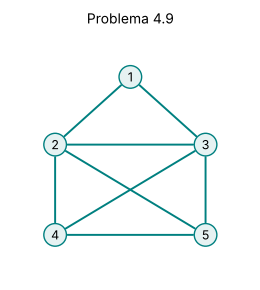

problema 4.9  {1: 2, 2: 4, 3: 4, 4: 3, 5: 3} -> cola
Königsberg    {'x': 3, 'y': 5, 'z': 3, 'w': 3} -> ninguno
pentágono     {1: 2, 2: 2, 3: 2, 4: 2, 5: 2} -> circuito
estrella      {1: 2, 2: 2, 3: 2, 4: 2, 5: 2} -> circuito


In [4]:
import math
V = [1, 2, 3, 4, 5]
A = [(1, 2), (1, 3), (2, 3), (2, 4), (2, 5), (3, 4), (3, 5), (4, 5)]
casa = {1: (1, 2.1), 2: (0, 1.2), 3: (2, 1.2), 4: (0, 0), 5: (2, 0)}
dibujar(casa, A, titulo="Problema 4.9")

K = ["x", "y", "z", "w"]
KA = [("x", "y"), ("x", "y"), ("y", "z"), ("y", "z"), ("x", "w"), ("y", "w"), ("z", "w")]
C5 = [1, 2, 3, 4, 5]
C5A = [(1, 2), (2, 3), (3, 4), (4, 5), (5, 1)]
estrella = [(1, 3), (3, 5), (5, 2), (2, 4), (4, 1)]
for nombre, (V_, A_) in {"problema 4.9": (V, A), "Königsberg": (K, KA),
                         "pentágono": (C5, C5A), "estrella": (C5, estrella)}.items():
    print(f"{nombre:<13}", grados(V_, A_), "->", clasificar_euler(V_, A_))

## 2. El algoritmo de Fleury

En cada paso se recorre una arista cuya eliminación no desconecte el grafo, salvo que sea la única que queda en el vértice. Una arista así, que al quitarla desconecta a sus extremos, es un **puente**.

In [5]:
def _alcanzables(x, aristas):
    vec = {}
    for a, b in aristas:
        vec.setdefault(a, set()).add(b)
        vec.setdefault(b, set()).add(a)
    visto, cola = {x}, deque([x])
    while cola:
        v = cola.popleft()
        for w in vec.get(v, ()):
            if w not in visto:
                visto.add(w)
                cola.append(w)
    return visto


def es_puente(arista, aristas):
    """¿Quitar esta arista (una copia) desconecta a sus extremos?"""
    x, y = arista
    resto = list(aristas)
    resto.remove(arista)
    return y not in _alcanzables(x, resto)


def fleury(vertices, aristas, inicio=None, eleccion=min, traza=False):
    """
    Algoritmo de Fleury. Empieza en un vértice de grado impar (si lo hay) y
    en cada paso recorre una arista cuya eliminación no desconecte el grafo,
    salvo que sea la única. Entre las posibles, `eleccion` decide (por
    defecto, el vecino de menor etiqueta). Devuelve la cola como lista.
    """
    if clasificar_euler(vertices, aristas) == "ninguno":
        raise ValueError("El grafo no tiene cola euleriana")
    resto = [tuple(a) for a in aristas]
    if inicio is None:
        impares = [x for x, g in grados(vertices, resto).items() if g % 2 == 1]
        inicio = min(impares) if impares else min(x for x in vertices if grados(vertices, resto)[x] > 0)
    x, cola = inicio, [inicio]
    while resto:
        salen = [a for a in resto if x in a]
        posibles = []
        for a in salen:
            y = a[1] if a[0] == x else a[0]
            if len(salen) == 1 or not es_puente(a, resto):
                posibles.append(y)
        y = eleccion(posibles)
        a = next(a for a in salen if (a[1] if a[0] == x else a[0]) == y)
        if traza:
            rechazadas = sorted({(b[1] if b[0] == x else b[0]) for b in salen} - set(posibles))
            nota = f"   (no: {', '.join(f'{x}-{r}' for r in rechazadas)}, es puente)" if rechazadas else ""
            print(f"  en {x}: puede ir a {sorted(set(posibles))}, va a {y}{nota}")
        resto.remove(a)
        cola.append(y)
        x = y
    return cola


def es_cola_euleriana(cola, aristas):
    """¿Recorre cada arista exactamente una vez?"""
    resto = [frozenset(a) if a[0] != a[1] else frozenset([a[0]]) for a in aristas]
    for x, y in zip(cola, cola[1:]):
        e = frozenset((x, y)) if x != y else frozenset([x])
        if e not in resto:
            return False
        resto.remove(e)
    return not resto

Con la elección por defecto (el vecino de menor etiqueta):

In [6]:
cola = fleury(V, A, traza=True)
print(cola, es_cola_euleriana(cola, A))

  en 4: puede ir a [2, 3, 5], va a 2
  en 2: puede ir a [1, 3, 5], va a 1
  en 1: puede ir a [3], va a 3
  en 3: puede ir a [2, 4, 5], va a 2
  en 2: puede ir a [5], va a 5
  en 5: puede ir a [3, 4], va a 3
  en 3: puede ir a [4], va a 4
  en 4: puede ir a [5], va a 5
[4, 2, 1, 3, 2, 5, 3, 4, 5] True


Eligiendo el vecino de mayor etiqueta aparece un puente: en el quinto paso, desde $2$, no se puede ir a $5$.

In [7]:
cola = fleury(V, A, eleccion=max, traza=True)
print(cola, es_cola_euleriana(cola, A))

  en 4: puede ir a [2, 3, 5], va a 5
  en 5: puede ir a [2, 3], va a 3
  en 3: puede ir a [1, 2, 4], va a 4
  en 4: puede ir a [2], va a 2
  en 2: puede ir a [1, 3], va a 3   (no: 2-5, es puente)
  en 3: puede ir a [1], va a 1
  en 1: puede ir a [2], va a 2
  en 2: puede ir a [5], va a 5
[4, 5, 3, 4, 2, 3, 1, 2, 5] True


La cola de las transparencias, $4-5-3-2-1-3-4-2-5$, también es válida:

In [8]:
print(es_cola_euleriana([4, 5, 3, 2, 1, 3, 4, 2, 5], A))

True


In [9]:
try:
    fleury(K, KA)
except ValueError as e:
    print("Königsberg:", e)

Königsberg: El grafo no tiene cola euleriana


## 3. El algoritmo de Hierholzer

Fleury comprueba en cada paso si una arista es puente, recorriendo el grafo: del orden de $|A|^2$ operaciones en total. Hierholzer (1873) avanza sin mirar hasta quedarse atascado y luego **empalma** los ciclos que quedan: cada arista se mira una vez.

In [10]:
def hierholzer(vertices, aristas, inicio=None):
    """
    Algoritmo de Hierholzer (1873): se avanza sin pensar hasta quedarse
    atascado y se empalman los ciclos que quedan. Cada arista se mira una vez.
    """
    if clasificar_euler(vertices, aristas) == "ninguno":
        raise ValueError("El grafo no tiene cola euleriana")
    incid = {x: [] for x in vertices}
    for num, (a, b) in enumerate(aristas):
        incid[a].append((num, b))
        incid[b].append((num, a))
    usada = [False] * len(aristas)
    if inicio is None:
        g = grados(vertices, aristas)
        impares = [x for x in vertices if g[x] % 2 == 1]
        inicio = impares[0] if impares else next(x for x in vertices if g[x] > 0)
    pila, cola = [inicio], []
    while pila:
        x = pila[-1]
        while incid[x] and usada[incid[x][-1][0]]:
            incid[x].pop()
        if incid[x]:
            num, y = incid[x].pop()
            usada[num] = True
            pila.append(y)
        else:
            cola.append(pila.pop())
    return cola[::-1]

In [11]:
print(hierholzer(V, A))
print(hierholzer(C5, estrella))

[4, 5, 3, 4, 2, 3, 1, 2, 5]
[1, 4, 2, 5, 3, 1]


### Comparación de tiempos

$K_n$ con $n$ impar es euleriano: cada vértice tiene grado $n-1$, que es par.

In [12]:
for n in (11, 21, 31, 41):
    Vn = list(range(n))
    An = [(i, j) for i in range(n) for j in range(i + 1, n)]
    t0 = time.perf_counter(); c1 = fleury(Vn, An, inicio=0); t1 = time.perf_counter()
    c2 = hierholzer(Vn, An, inicio=0); t2 = time.perf_counter()
    assert es_cola_euleriana(c1, An) and es_cola_euleriana(c2, An)
    print(f"K_{n}: {len(An):>4} aristas | Fleury {t1 - t0:7.3f} s | Hierholzer {t2 - t1:.5f} s")

K_11:   55 aristas | Fleury   0.006 s | Hierholzer 0.00009 s
K_21:  210 aristas | Fleury   0.078 s | Hierholzer 0.00024 s


K_31:  465 aristas | Fleury   0.500 s | Hierholzer 0.00044 s


K_41:  820 aristas | Fleury   1.968 s | Hierholzer 0.00075 s


## 4. Grafos hamiltonianos

Vuelta atrás: se alarga el camino con un vecino no visitado; si no se puede seguir, se deshace el último paso. En el peor caso, del orden de $n!$ intentos.

In [13]:
def hamiltoniano(vertices, aristas, ciclo=True):
    """
    Busca un ciclo (o un camino) hamiltoniano por vuelta atrás.
    En el peor caso prueba del orden de n! ordenaciones.
    """
    vec = {x: set() for x in vertices}
    for a, b in aristas:
        if a != b:
            vec[a].add(b)
            vec[b].add(a)
    n = len(vertices)
    inicios = vertices[:1] if ciclo else vertices

    def extender(camino, usados):
        if len(camino) == n:
            if not ciclo or camino[0] in vec[camino[-1]]:
                return camino + ([camino[0]] if ciclo else [])
            return None
        for y in sorted(vec[camino[-1]] - usados, key=str):
            r = extender(camino + [y], usados | {y})
            if r:
                return r
        return None

    for s in inicios:
        r = extender([s], {s})
        if r:
            return r
    return None

In [14]:
K5A = [(i, j) for i in range(1, 6) for j in range(i + 1, 6)]
B = [1, 2, 3, 4, 5, 6]
BA = [(1, 2), (2, 3), (3, 1), (3, 4), (4, 5), (5, 6), (6, 4)]        # dos triángulos unidos
S = [0, 1, 2, 3, 4, 5]
SA = [(1, 2), (2, 3), (3, 1), (1, 0), (2, 4), (3, 5)]                # triángulo con tres hojas
for nombre, (V_, A_) in {"C5": (C5, C5A), "K5": (C5, K5A), "dos triángulos": (B, BA),
                         "triángulo con hojas": (S, SA)}.items():
    print(f"{nombre:<20} ciclo: {hamiltoniano(V_, A_)}   camino: {hamiltoniano(V_, A_, ciclo=False)}")

C5                   ciclo: [1, 2, 3, 4, 5, 1]   camino: [1, 2, 3, 4, 5]
K5                   ciclo: [1, 2, 3, 4, 5, 1]   camino: [1, 2, 3, 4, 5]
dos triángulos       ciclo: None   camino: [1, 2, 3, 4, 5, 6]
triángulo con hojas  ciclo: None   camino: None


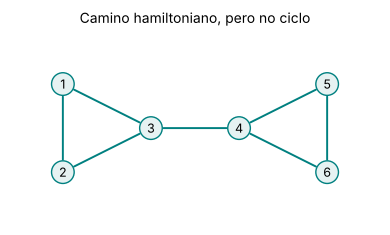

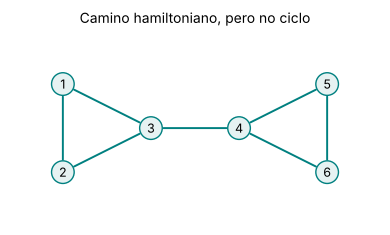

In [15]:
dibujar({1: (0, 1), 2: (0, 0), 3: (1, 0.5), 4: (2, 0.5), 5: (3, 1), 6: (3, 0)}, BA,
        titulo="Camino hamiltoniano, pero no ciclo")

## 5. Condiciones suficientes (teorema 4.30)

Si $G$ es simple y conexo con $n\ge 3$ vértices, cualquiera de estas condiciones garantiza que es hamiltoniano:

1. $gr(x)+gr(y)\ge n$ para cada par de vértices no adyacentes (Ore);
2. $gr(x)\ge n/2$ para todo $x$ (Dirac);
3. $|A|\ge\binom{n-1}{2}+2$.

No son necesarias: $C_5$ es hamiltoniano y no cumple ninguna.

In [16]:
def condiciones_suficientes(vertices, aristas):
    """Las tres condiciones del teorema 4.30 (grafo simple y conexo)."""
    n = len(vertices)
    g = grados(vertices, aristas)
    E = {frozenset(a) for a in aristas}
    no_adyacentes = [(x, y) for i, x in enumerate(vertices) for y in vertices[i + 1:]
                     if frozenset((x, y)) not in E]
    return {
        "1. gr(x)+gr(y) >= n si no adyacentes": all(g[x] + g[y] >= n for x, y in no_adyacentes),
        "2. gr(x) >= n/2 para todo x": all(2 * g[x] >= n for x in vertices),
        "3. |A| >= C(n-1,2) + 2": len(set(E)) >= comb(n - 1, 2) + 2,
    }

In [17]:
for nombre, (V_, A_) in {"C5": (C5, C5A), "K5": (C5, K5A)}.items():
    print(nombre, condiciones_suficientes(V_, A_))

C5 {'1. gr(x)+gr(y) >= n si no adyacentes': False, '2. gr(x) >= n/2 para todo x': False, '3. |A| >= C(n-1,2) + 2': False}
K5 {'1. gr(x)+gr(y) >= n si no adyacentes': True, '2. gr(x) >= n/2 para todo x': True, '3. |A| >= C(n-1,2) + 2': True}


Comprobación: entre todos los grafos simples con $5$ vértices, ¿cuántos son hamiltonianos y cuántos cumplen cada condición?

In [18]:
from itertools import combinations
V5 = [1, 2, 3, 4, 5]
posibles = list(combinations(V5, 2))
cuenta = {"hamiltonianos": 0, "Ore": 0, "Dirac": 0, "aristas": 0}
for m in range(len(posibles) + 1):
    for A_ in combinations(posibles, m):
        A_ = list(A_)
        if not es_conexo(V5, A_) or any(grados(V5, A_)[x] == 0 for x in V5):
            continue
        h = hamiltoniano(V5, A_) is not None
        cs = list(condiciones_suficientes(V5, A_).values())
        assert not any(cs) or h                    # si alguna se cumple, es hamiltoniano
        cuenta["hamiltonianos"] += h
        for k, v in zip(["Ore", "Dirac", "aristas"], cs):
            cuenta[k] += v
print(cuenta)

{'hamiltonianos': 218, 'Ore': 86, 'Dirac': 26, 'aristas': 56}


Ninguna condición falla (el `assert` no salta), pero las tres se quedan cortas: hay grafos hamiltonianos que no cumplen ninguna.

## Un problema completo: 4.17

Cinco ciudades unidas por carreteras (en cientos de km). ¿Se pueden recorrer todas las carreteras sin repetir? ¿Y visitar todas las ciudades sin repetir?

In [19]:
Vc = list("ABCDE")
Ac = [("A", "B"), ("A", "D"), ("B", "C"), ("B", "D"), ("C", "E"), ("E", "D")]
print(grados(Vc, Ac), clasificar_euler(Vc, Ac))
print("cola euleriana:", fleury(Vc, Ac))
print("camino hamiltoniano:", hamiltoniano(Vc, Ac, ciclo=False))
print("ciclo hamiltoniano:", hamiltoniano(Vc, Ac))

{'A': 2, 'B': 3, 'C': 2, 'D': 3, 'E': 2} cola
cola euleriana: ['B', 'A', 'D', 'B', 'C', 'E', 'D']
camino hamiltoniano: ['A', 'B', 'C', 'E', 'D']
ciclo hamiltoniano: ['A', 'B', 'C', 'E', 'D', 'A']


Sólo $B$ y $D$ tienen grado impar, así que hay cola euleriana de $B$ a $D$. Hay camino hamiltoniano, y de hecho también ciclo: $A\,B\,C\,E\,D\,A$.

## Referencias

- Euler, L. (1736). Solutio problematis ad geometriam situs pertinentis. *Commentarii academiae scientiarum Petropolitanae*, 8, 128–140.
- Hierholzer, C. y Wiener, C. (1873). Ueber die Möglichkeit, einen Linienzug ohne Wiederholung und ohne Unterbrechung zu umfahren. *Mathematische Annalen*, 6, 30–32.
- Grimaldi, R. P. (1998). *Matemática discreta y combinatoria* (3ª ed.). Addison Wesley Longman. Capítulo 11.